# 1) Chargement des données

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH =r"....."

if not os.path.exists(DATA_PATH):
    print(f"❌ Attention : le fichier '{DATA_PATH}' n'existe pas.")

try:
    df = pd.read_csv(DATA_PATH, sep=";")
    print("✅ Données chargées :", df.shape)
    display(df.head())
except Exception as e:
    print("❌ Erreur lors du chargement :", e)

✅ Données chargées : (1500, 7)


,is_genuine,diagonal,height_left,height_right,margin_low,margin_up,length
0,True,171.81,104.86,104.95,4.52,2.89,112.83
1,True,171.46,103.36,103.66,3.77,2.99,113.09
2,True,172.69,104.48,103.50,4.40,2.94,113.16
3,True,171.36,103.91,103.94,3.62,3.01,113.51
4,True,171.73,104.28,103.46,4.04,3.48,112.54


# 2) Analyse exploratoire (EDA)


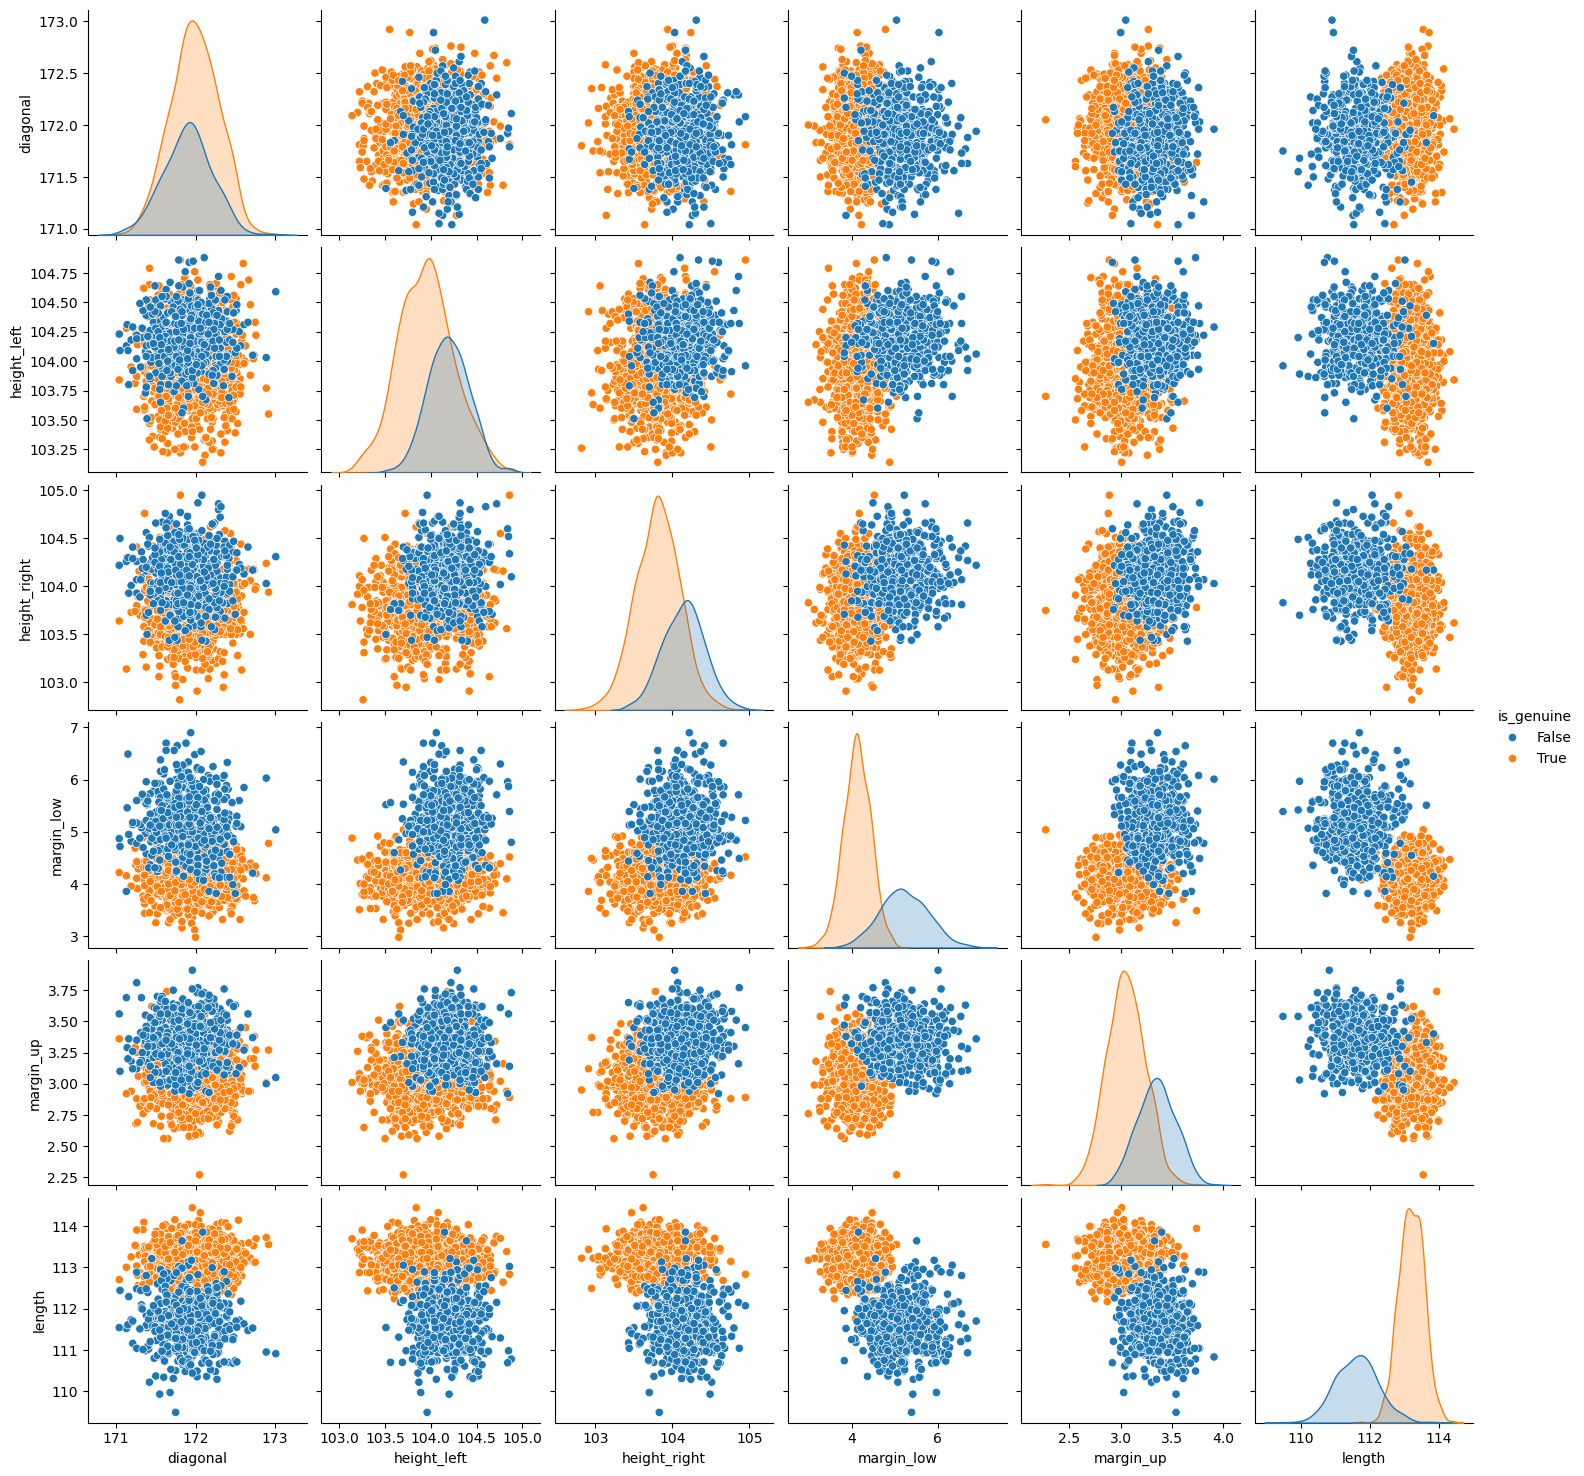

In [4]:
sns.pairplot(df, hue='is_genuine')

<div style="background-color:#A5D6A7; padding:20px; border-left:6px solid #2E7D32; border-radius:8px;">

### Analyse des distributions par classe

La visualisation des distributions met en évidence des différences entre les classes, principalement liées à la **valeur réelle des variables métriques**.

Certaines variables et certaines paires de variables semblent cependant **mieux séparer les classes** que d'autres.

**Hypothèse :** certaines variables sont plus discriminantes que d'autres.

Nous allons tester cette hypothèse dans la suite de l'analyse.

</div>

<div style="background-color:#4A4A4A; padding:20px; border-left:6px solid #212121; border-radius:8px; color:white;">

### Overlap coefficient (OVL)

Pour mesurer le pouvoir discriminant des variables, nous allons utiliser l'**Overlap coefficient (OVL)**.

Pour un couple \((X_i, X_j)\), on estime la densité 2D de chaque classe par **KDE** (`scipy.stats.gaussian_kde` ou `sklearn.neighbors.KernelDensity`), sur une grille commune, puis :

\[
OVL = | A ∩ B | / min( | A |, | B |)
\]

Le score est compris entre **0 et 1** :

- **0** → séparation parfaite entre les classes
- **1** → superposition totale des distributions

Ainsi, pour classer les couples de variables par **pouvoir discriminant**, nous trierons les résultats par **OVL croissant**.

### Points pratiques

- **Grille commune :** la grille doit être identique pour les deux classes (mêmes bornes et même pas). Sans cela, la comparaison des densités n'a pas de sens.
- **Bandwidth du KDE :** il faut choisir ce paramètre avec attention.
  - Trop petit → risque de **surestimer la séparation**, avec des densités très fragmentées qui se recouvrent peu par hasard.
  - Trop grand → risque de **trop lisser les distributions** et donc de sous-estimer leur pouvoir discriminant.

</div>

On va normaliser tout de suite pour pour que le KDE ait du sens

In [8]:
from sklearn.preprocessing import StandardScaler

In [9]:
cols = [
    'is_genuine',
    'diagonal',
    'height_left',
    'height_right',
    'margin_low',
    'margin_up',
    'length',
]

In [10]:
 # Normalisation (uniquement des variables continues, is_genuine reste à part)

feature_cols = [c for c in cols if c != "is_genuine"]
X = df[cols].dropna()
scaler = StandardScaler()
X_scaled = X.copy()
X_scaled[feature_cols] = scaler.fit_transform(X[feature_cols])

In [11]:
import itertools
from scipy.stats import gaussian_kde


def compute_ovl(x0, x1, grid_size=100, bw_method=None):
    """
    Calcule l'Overlap Coefficient (OVL) entre deux nuages de points 2D
    via estimation de densité par KDE sur une grille commune.

    Parameters
    ----------
    x0, x1 : arrays (n, 2)
        Points des deux classes pour un couple de variables donné.
    grid_size : int
        Résolution de la grille (grid_size x grid_size).
    bw_method : str, float ou None
        Méthode de bandwidth passée à gaussian_kde (None = Scott's rule).

    Returns
    -------
    ovl : float
        Score entre 0 (séparation parfaite) et 1 (superposition totale).
    """
    # KDE par classe
    kde0 = gaussian_kde(x0.T, bw_method=bw_method)
    kde1 = gaussian_kde(x1.T, bw_method=bw_method)

    # Grille commune, bornée sur l'union des deux nuages (+ marge)
    all_pts = np.vstack([x0, x1])
    x_min, y_min = all_pts.min(axis=0)
    x_max, y_max = all_pts.max(axis=0)
    x_margin = (x_max - x_min) * 0.1
    y_margin = (y_max - y_min) * 0.1

    xx, yy = np.meshgrid(
        np.linspace(x_min - x_margin, x_max + x_margin, grid_size),
        np.linspace(y_min - y_margin, y_max + y_margin, grid_size),
    )
    grid_pts = np.vstack([xx.ravel(), yy.ravel()]) ### Là on aura définit la taille des grilles

    f0 = kde0(grid_pts).reshape(xx.shape) ### Application du KDE à la grille pour la classe 0
    f1 = kde1(grid_pts).reshape(xx.shape) ### Application du KDE à la grille pour la classe 1

    # Normalisation numérique pour que chaque densité s'intègre à ~1 sur la grille
    dx = (x_max + x_margin - (x_min - x_margin)) / grid_size  ### calcul de la base des cellules
    dy = (y_max + y_margin - (y_min - y_margin)) / grid_size  ### calcul du côté des cellules
    cell_area = dx * dy

    ### Normalisation pour obtenir deux vraies distributions de probabilité # dont l'intégrale sur la grille vaut 1
    f0 = f0 / (f0.sum() * cell_area)
    f1 = f1 / (f1.sum() * cell_area)

    ovl = np.minimum(f0, f1).sum() * cell_area ### Pour chaque cellule on choisit la plus petite densité, on somme et on multiplie par la taille
    ### d'une cellule
    return float(np.clip(ovl, 0, 1))


def rank_pairs_by_ovl(df, feature_cols, target_col, grid_size=100, bw_method=None):
    """
    Calcule l'OVL pour chaque couple de variables continues, en scindant
    les nuages selon target_col (variable binaire).

    Returns
    -------
    DataFrame trié par OVL croissant (pouvoir discriminant décroissant).
    """
    results = []
    classes = df[target_col].unique()
    assert len(classes) == 2, "target_col doit être binaire"
    # Récupération des deux modalités de la variable cible (0 et 1)
    c0, c1 = classes
         
    for xi, xj in itertools.combinations(feature_cols, 2):
        sub = df[[xi, xj, target_col]].dropna()
        # Extraction des observations des deux variables pour la classe 0
        x0 = sub.loc[sub[target_col] == c0, [xi, xj]].values
        # Extraction des observations des deux variables pour la classe 1
        x1 = sub.loc[sub[target_col] == c1, [xi, xj]].values

        # KDE 2D nécessite plus de points que de dimensions, et une variance non nulle
        if len(x0) < 5 or len(x1) < 5:
            continue

        try:
            ovl = compute_ovl(x0, x1, grid_size=grid_size, bw_method=bw_method)
        except np.linalg.LinAlgError:
            # covariance singulière (ex: variable quasi-constante dans une classe)
            continue

        results.append({"var_1": xi, "var_2": xj, "ovl": ovl})
    ### Transforme la liste en dataframe pour affichage
    res_df = pd.DataFrame(results).sort_values("ovl", ascending=True).reset_index(drop=True)
    res_df["rank"] = res_df.index + 1
    return res_df


if __name__ == "__main__":
    
    cols = [
        'is_genuine',
        'diagonal',
        'height_left',
        'height_right',
        'margin_low',
        'margin_up',
        'length',
    ]

    ranking = rank_pairs_by_ovl(
        X_scaled,
        feature_cols=feature_cols,
        target_col='is_genuine',
        grid_size=100,
    )

    print(ranking.to_string(index=False))

       var_1        var_2      ovl  rank
  margin_low       length 0.038887     1
   margin_up       length 0.079744     2
height_right       length 0.102533     3
 height_left       length 0.106888     4
    diagonal       length 0.117098     5
  margin_low    margin_up 0.140728     6
height_right   margin_low 0.184384     7
 height_left   margin_low 0.192881     8
    diagonal   margin_low 0.212973     9
height_right    margin_up 0.344709    10
 height_left    margin_up 0.371185    11
    diagonal    margin_up 0.428054    12
 height_left height_right 0.474387    13
    diagonal height_right 0.553693    14
    diagonal  height_left 0.608138    15


Maintenant qu'on a examiné les paires, on va pouvoir comparer ça avec le pouvoir discriminant des variables univariées, pour voir si on a un gain de précision et si oui, avec quelles paires. 

In [13]:
def compute_ovl_1d(x0, x1, grid_size=1000, bw_method=None):
    """
    OVL univarié (1D) entre deux échantillons, même logique que compute_ovl
    mais sur une seule dimension.
    """
    kde0 = gaussian_kde(x0, bw_method=bw_method)
    kde1 = gaussian_kde(x1, bw_method=bw_method)

    all_pts = np.concatenate([x0, x1])
    x_min, x_max = all_pts.min(), all_pts.max()
    margin = (x_max - x_min) * 0.1

    grid = np.linspace(x_min - margin, x_max + margin, grid_size)
    dx = grid[1] - grid[0]

    f0 = kde0(grid)
    f1 = kde1(grid)

    f0 = f0 / (f0.sum() * dx)
    f1 = f1 / (f1.sum() * dx)

    ovl = np.minimum(f0, f1).sum() * dx
    return float(np.clip(ovl, 0, 1))


def rank_features_by_ovl_1d(df, feature_cols, target_col, grid_size=1000, bw_method=None):
    """
    Calcule l'OVL univarié pour chaque variable individuellement.

    Returns
    -------
    DataFrame trié par OVL croissant (pouvoir discriminant décroissant).
    """
    results = []
    classes = df[target_col].unique()
    assert len(classes) == 2, "target_col doit être binaire"
    c0, c1 = classes

    for xi in feature_cols:
        sub = df[[xi, target_col]].dropna()
        x0 = sub.loc[sub[target_col] == c0, xi].values
        x1 = sub.loc[sub[target_col] == c1, xi].values

        if len(x0) < 5 or len(x1) < 5:
            continue

        try:
            ovl = compute_ovl_1d(x0, x1, grid_size=grid_size, bw_method=bw_method)
        except np.linalg.LinAlgError:
            continue

        results.append({"var": xi, "ovl_1d": ovl})

    res_df = pd.DataFrame(results).sort_values("ovl_1d", ascending=True).reset_index(drop=True)
    res_df["rank_1d"] = res_df.index + 1
    return res_df



if __name__ == "__main__":
    
    cols = [
        'is_genuine',
        'diagonal',
        'height_left',
        'height_right',
        'margin_low',
        'margin_up',
        'length',
    ]

    univariate = rank_features_by_ovl_1d(
        X_scaled,
        feature_cols=feature_cols,
        target_col='is_genuine',
    )


    print("--- OVL univarié (variable seule) ---")
    print(univariate.to_string(index=False))
    print("\n--- OVL par couple, avec gain vs meilleure variable seule ---")
    print(ranking.to_string(index=False))

--- OVL univarié (variable seule) ---
         var   ovl_1d  rank_1d
      length 0.112310        1
  margin_low 0.209735        2
   margin_up 0.440236        3
height_right 0.565595        4
 height_left 0.641960        5
    diagonal 0.887610        6

--- OVL par couple, avec gain vs meilleure variable seule ---
       var_1        var_2      ovl  rank
  margin_low       length 0.038887     1
   margin_up       length 0.079744     2
height_right       length 0.102533     3
 height_left       length 0.106888     4
    diagonal       length 0.117098     5
  margin_low    margin_up 0.140728     6
height_right   margin_low 0.184384     7
 height_left   margin_low 0.192881     8
    diagonal   margin_low 0.212973     9
height_right    margin_up 0.344709    10
 height_left    margin_up 0.371185    11
    diagonal    margin_up 0.428054    12
 height_left height_right 0.474387    13
    diagonal height_right 0.553693    14
    diagonal  height_left 0.608138    15


Le gain par rapport à la meilleure variable isolée existe pour les paires suivantes : 
margin_low       length 0.038887     
margin_up       length 0.079744     
height_right       length 0.102533     
height_left       length 0.106888     

Pour visualiser par curiosité : 

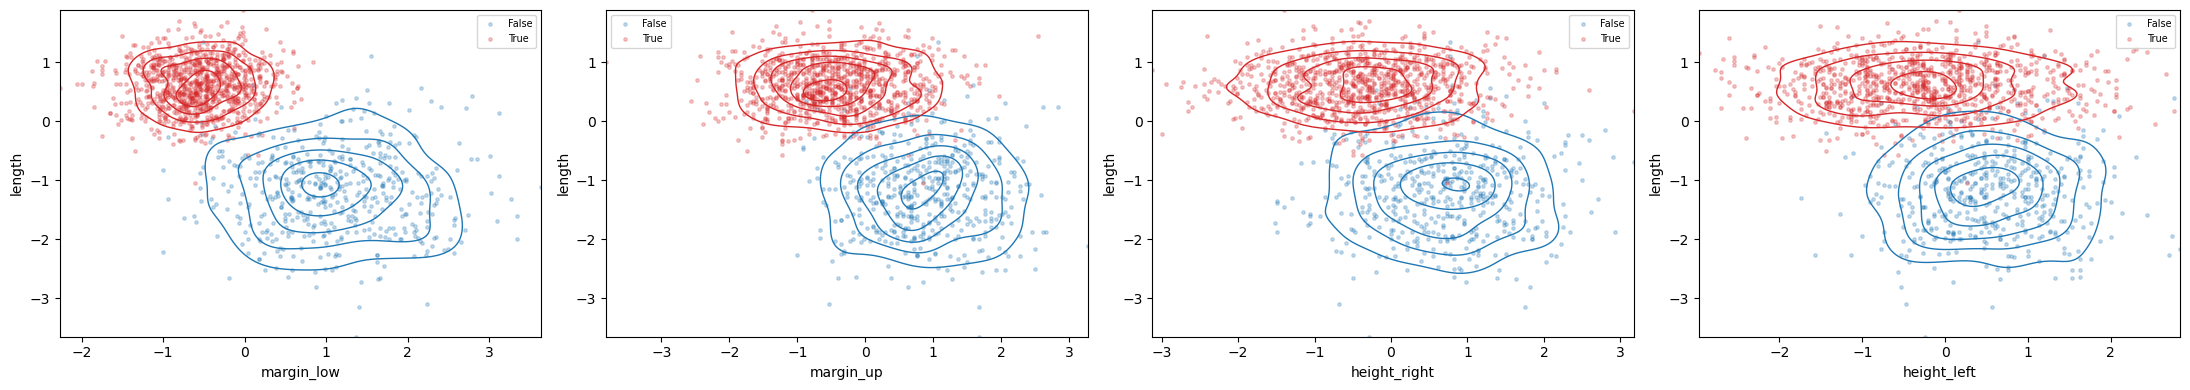

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

pairs = [
    ("margin_low", "length"),
    ("margin_up", "length"),
    ("height_right", "length"),
    ("height_left", "length"),
]

fig, axes = plt.subplots(1, 4, figsize=(22, 4))

for ax, (xi, xj) in zip(axes, pairs):
    x0 = X_scaled.loc[X_scaled["is_genuine"] == False, [xi, xj]].values
    x1 = X_scaled.loc[X_scaled["is_genuine"] == True, [xi, xj]].values

    kde0 = gaussian_kde(x0.T)
    kde1 = gaussian_kde(x1.T)

    x_min, y_min = np.vstack([x0, x1]).min(axis=0)
    x_max, y_max = np.vstack([x0, x1]).max(axis=0)
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 150), np.linspace(y_min, y_max, 150))
    grid = np.vstack([xx.ravel(), yy.ravel()])

    f0 = kde0(grid).reshape(xx.shape)
    f1 = kde1(grid).reshape(xx.shape)

    ax.scatter(*x0.T, s=6, alpha=0.25, color="#1f77b4", label="False")
    ax.scatter(*x1.T, s=6, alpha=0.25, color="#d62728", label="True")
    ax.contour(xx, yy, f0, levels=5, colors="#1f77b4", linewidths=1)
    ax.contour(xx, yy, f1, levels=5, colors="#d62728", linewidths=1)
    ax.set_xlabel(xi)
    ax.set_ylabel(xj)
    ax.legend(fontsize=7)

fig.tight_layout()
plt.show()

<div style="background-color:#A5D6A7; padding:20px; border-left:6px solid #2E7D32; border-radius:8px;">

### Protocole de comparaison des modèles

On remarque ici qu'il existe **4 paires de variables** pour lesquelles la distinction entre les classes est meilleure en combinant les deux variables qu'avec la meilleure variable prise individuellement.

Pour les modèles testés, nous proposons donc le protocole suivant.

**1. Modèle de référence — Dumb model**

Utiliser la **meilleure variable unique** comme base de comparaison.

**2. Modèle sur l'ensemble des variables**

Entraîner un modèle en utilisant **toutes les variables disponibles**.

**3. Modèle sur les 4 couples sélectionnés**

Entraîner un modèle en utilisant uniquement les **4 paires de variables (donc 5 variables sur 6) identifiées comme les plus discriminantes**.

**4. Evaluation sur 5 folds pour pouvoir mesurer l'écart type**

L'objectif sera de comparer les performances de ces trois approches afin de déterminer si la sélection des couples de variables apporte un réel gain par rapport à l'utilisation d'une seule variable ou de l'ensemble des variables.

</div>

In [18]:
X_scaled_all = X_scaled
X_scaled_dumb = X_scaled[['is_genuine', 'length']]
X_scaled_four = X_scaled[['is_genuine', 'length', 'margin_low', 'margin_up', 'height_right', 'height_left']]

In [19]:
X_all = X_scaled_all[['length', 'margin_low', 'margin_up', 'height_right', 'height_left', 'diagonal']] 
y_all = X_scaled_all["is_genuine"] 
X_dumb = X_scaled_dumb[['length']]
y_dumb = X_scaled_dumb['is_genuine']
X_four = X_scaled_four[['length', 'margin_low', 'margin_up', 'height_right', 'height_left']]
y_four = X_scaled_four['is_genuine']

In [20]:
print("X_all :", X_all.shape)
print("y_all :", y_all.shape)

print("\nRépartition de y_all :")
print(y_all.value_counts())
print("\nProportions :")
print(y_all.value_counts(normalize=True))

X_all : (1463, 6)
y_all : (1463,)

Répartition de y_all :
is_genuine
True     971
False    492
Name: count, dtype: int64

Proportions :
is_genuine
True     0.663705
False    0.336295
Name: proportion, dtype: float64


In [21]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all,
    test_size=0.5,
    random_state=42,
    stratify=y_all
)

X_train_dumb, X_test_dumb, y_train_dumb, y_test_dumb = train_test_split(
    X_dumb, y_dumb,
    test_size=0.5,
    random_state=42,
    stratify=y_dumb
)

X_train_four, X_test_four, y_train_four, y_test_four = train_test_split(
    X_four, y_four,
    test_size=0.5,
    random_state=42,
    stratify=y_four
)

In [22]:
print(y_test.value_counts())
print(y_test_four.value_counts())
print(y_test_dumb.value_counts())

is_genuine
True     486
False    246
Name: count, dtype: int64
is_genuine
True     486
False    246
Name: count, dtype: int64
is_genuine
True     486
False    246
Name: count, dtype: int64


Enfin, on met toutes les variables sur la même échelle (moyenne = 0, écart-type = 1).

➡️ Pourquoi ?
Parce que certains modèles, comme le KNN ou la Régression Logistique, sont sensibles aux différences d’échelle.
Sans standardisation, la variable la plus grande numériquement prend trop d’importance.

# Use scaler on X_train and X_test.

Déjà fait

# 4) Modélisation

Dans tous domaines, vous ne pouvez pas progresser si vous ne comprenez pas comment vos outils fonctionnent.

Avant d'utiliser les modèles mathématiques qui suivent, je vous recommande donc de visionner les vidéos suivantes:
* [StatQuest: Logistic Regression](https://www.youtube.com/watch?v=yIYKR4sgzI8)
* [StatQuest: K-nearest neighbors, Clearly Explained](https://youtu.be/HVXime0nQeI)
* [StatQuest: Random Forests Part 1 - Building, Using and Evaluating](https://youtu.be/J4Wdy0Wc_xQ)
* [StatQuest: Random Forests Part 2: Missing data and clustering](https://www.youtube.com/watch?v=sQ870aTKqiM)
* [StatQuest: K-means clustering](https://youtu.be/4b5d3muPQmA)

In [26]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict

cv_configs = {
    "Dumb model": (LogisticRegression(max_iter=1000), X_dumb, y_dumb),
    "4 couples": (LogisticRegression(max_iter=1000), X_four, y_four),
    "Toutes les variables": (LogisticRegression(max_iter=1000), X_all, y_all),
}
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ["accuracy", "precision", "recall", "f1"]
cv_results = {}
for name, (model, X, y) in cv_configs.items():
    scores = cross_validate(model, X, y, cv=skf, scoring=scoring)
    cv_results[name] = scores
    print(f"\n{'=' * 60}")
    print(f"  {name}")
    print(f"{'=' * 60}")
    for metric in scoring:
        vals = scores[f"test_{metric}"]
        print(f"  {metric:10s} : {vals.mean():.3f} (+/- {vals.std():.3f})  |  folds: {np.round(vals, 3)}")


  Dumb model
  accuracy   : 0.956 (+/- 0.003)  |  folds: [0.952 0.959 0.959 0.955 0.955]
  precision  : 0.957 (+/- 0.008)  |  folds: [0.941 0.96  0.96  0.964 0.959]
  recall     : 0.978 (+/- 0.007)  |  folds: [0.99  0.979 0.979 0.969 0.974]
  f1         : 0.967 (+/- 0.002)  |  folds: [0.965 0.969 0.969 0.967 0.967]

  4 couples
  accuracy   : 0.992 (+/- 0.003)  |  folds: [0.986 0.997 0.993 0.99  0.993]
  precision  : 0.991 (+/- 0.007)  |  folds: [0.98  1.    0.995 0.99  0.99 ]
  recall     : 0.997 (+/- 0.003)  |  folds: [1.    0.995 0.995 0.995 1.   ]
  f1         : 0.994 (+/- 0.003)  |  folds: [0.99  0.997 0.995 0.992 0.995]

  Toutes les variables
  accuracy   : 0.991 (+/- 0.005)  |  folds: [0.983 0.997 0.993 0.99  0.993]
  precision  : 0.991 (+/- 0.007)  |  folds: [0.98  1.    0.995 0.99  0.99 ]
  recall     : 0.996 (+/- 0.002)  |  folds: [0.995 0.995 0.995 0.995 1.   ]
  f1         : 0.993 (+/- 0.003)  |  folds: [0.987 0.997 0.995 0.992 0.995]


In [27]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict

knn_cv_configs = {
    "KNN Dumb model": (KNeighborsClassifier(n_neighbors=5), X_dumb, y_dumb),
    "KNN 4 couples": (KNeighborsClassifier(n_neighbors=5), X_four, y_four),
    "KNN Toutes les variables": (KNeighborsClassifier(n_neighbors=5), X_all, y_all),
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ["accuracy", "precision", "recall", "f1"]

knn_cv_results = {}

for name, (model, X, y) in knn_cv_configs.items():
    scores = cross_validate(model, X, y, cv=skf, scoring=scoring)
    knn_cv_results[name] = scores

    print(f"\n{'=' * 60}")
    print(f"  {name}")
    print(f"{'=' * 60}")
    for metric in scoring:
        vals = scores[f"test_{metric}"]
        print(f"  {metric:10s} : {vals.mean():.3f} (+/- {vals.std():.3f})  |  folds: {np.round(vals, 3)}")


  KNN Dumb model
  accuracy   : 0.955 (+/- 0.007)  |  folds: [0.949 0.952 0.959 0.966 0.949]
  precision  : 0.952 (+/- 0.012)  |  folds: [0.933 0.95  0.96  0.969 0.95 ]
  recall     : 0.981 (+/- 0.007)  |  folds: [0.995 0.979 0.979 0.979 0.974]
  f1         : 0.967 (+/- 0.005)  |  folds: [0.963 0.964 0.969 0.974 0.962]

  KNN 4 couples
  accuracy   : 0.990 (+/- 0.004)  |  folds: [0.986 0.99  0.997 0.986 0.99 ]
  precision  : 0.988 (+/- 0.005)  |  folds: [0.98  0.99  0.995 0.99  0.985]
  recall     : 0.997 (+/- 0.004)  |  folds: [1.    0.995 1.    0.99  1.   ]
  f1         : 0.992 (+/- 0.003)  |  folds: [0.99  0.992 0.997 0.99  0.992]

  KNN Toutes les variables
  accuracy   : 0.988 (+/- 0.006)  |  folds: [0.98  0.99  0.997 0.986 0.99 ]
  precision  : 0.986 (+/- 0.007)  |  folds: [0.975 0.99  0.995 0.985 0.985]
  recall     : 0.997 (+/- 0.003)  |  folds: [0.995 0.995 1.    0.995 1.   ]
  f1         : 0.991 (+/- 0.004)  |  folds: [0.985 0.992 0.997 0.99  0.992]


<div style="background-color:#A5D6A7; padding:20px; border-left:6px solid #2E7D32; border-radius:8px;">



Le Random Forest est un cas particulier. Plusieurs paramètres nécessitent d'être ajustés pour un usage pertinent. C'est également le modèle le plus à même de surraprendre. 

Dans un premier temps on va tester l'influence des principaux paramètres. 

En fonction des résultats on testera plusieurs combinaisons sur des plages de valeurs restreintes par la première exploration puis on selectionnera la meilleure combinaison.

Enfin on entrainera le modèle sur la meilleure combinaison trouvée.

Nota Bene : Pour éviter le surraprentissage, nous ne testons ni ne sélectionnons de min_sample_leaf < 4 pour l'entrainement. Un min_sample_leaf trop faible autorise en effet l'isolement de cas particuliers et ne garantit pas un apprentissage des règles générales de distinction. 

</div>

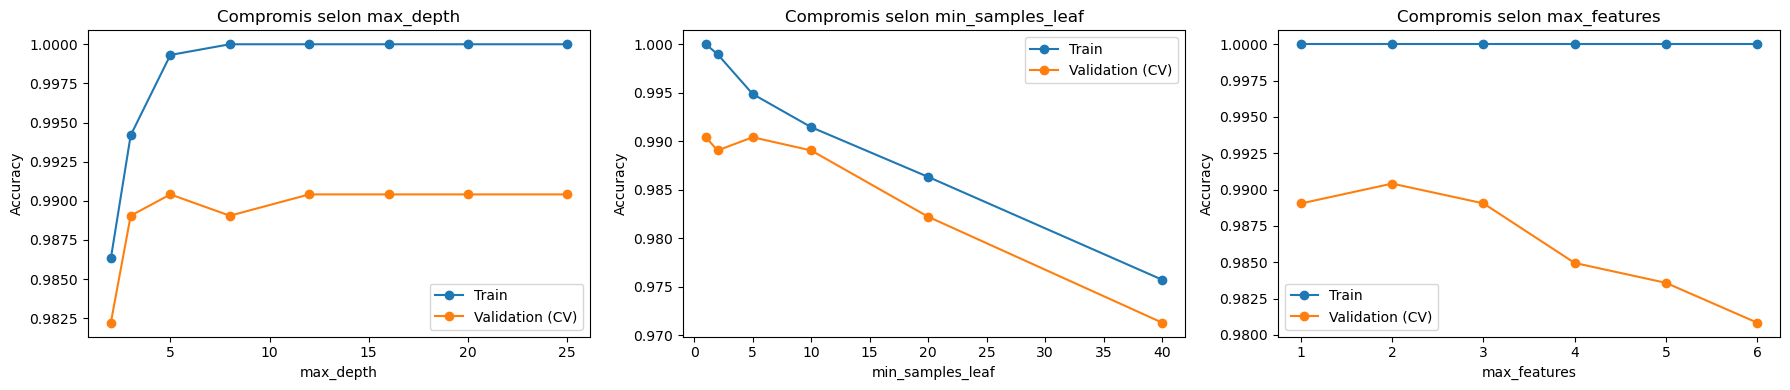

RandomForestClassifier(random_state=42)

In [29]:
from sklearn.model_selection import validation_curve
from sklearn.ensemble import RandomForestClassifier


param_configs = {
    "max_depth": {
        "param_range": [2, 3, 5, 8, 12, 16, 20, None],
        "plot_range": [2, 3, 5, 8, 12, 16, 20, 25],
    },
    "min_samples_leaf": {
        "param_range": [1, 2, 5, 10, 20, 40],
        "plot_range": [1, 2, 5, 10, 20, 40],
    },
    "max_features": {
        "param_range": [1, 2, 3, 4, 5, 6],
        "plot_range": [1, 2, 3, 4, 5, 6],
    },
}

fig, axes = plt.subplots(1, len(param_configs), figsize=(18, 4))

for ax, (param_name, config) in zip(axes, param_configs.items()):
    train_scores, test_scores = validation_curve(
        RandomForestClassifier(n_estimators=100, random_state=42),
        X_train, y_train,
        param_name=param_name,
        param_range=config["param_range"],
        cv=5,
        scoring="accuracy",
        n_jobs=-1,
    )

    ax.plot(config["plot_range"], train_scores.mean(axis=1), label="Train", marker="o")
    ax.plot(config["plot_range"], test_scores.mean(axis=1), label="Validation (CV)", marker="o")
    ax.set_xlabel(param_name)
    ax.set_ylabel("Accuracy")
    ax.legend()
    ax.set_title(f"Compromis selon {param_name}")

plt.tight_layout()
plt.show()

# Création et entraînement du modèle final
rf_best = RandomForestClassifier(n_estimators=100, random_state=42)
rf_best.fit(X_train, y_train)

In [30]:
importances = pd.Series(rf_best.feature_importances_, index=X_train.columns).sort_values(ascending=False)
print(importances)

length          0.475328
margin_low      0.291715
margin_up       0.117806
height_right    0.065651
height_left     0.041376
diagonal        0.008124
dtype: float64


In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "max_depth": [3, 4, 5, 6, 7],
    "min_samples_leaf": [4, 5, 6],
    "max_features": [1, 2, 3],
    "n_estimators": [50, 100, 150, 200],
}

grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring="accuracy",  
    n_jobs=-1,
)

grid_search.fit(X_train, y_train)

print("Meilleurs paramètres :", grid_search.best_params_)
print("Meilleur score CV :", grid_search.best_score_)

rf_best = grid_search.best_estimator_

In [32]:
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict


rf_cv_configs = {
    "RF Dumb model": (
        RandomForestClassifier(n_estimators=50, max_depth=5, max_features=2, min_samples_leaf=5, random_state=42),
        X_dumb, y_dumb
    ),
    "RF 4 couples": (
        RandomForestClassifier(n_estimators=50, max_depth=5, max_features=2, min_samples_leaf=5, random_state=42),
        X_four, y_four
    ),
    "RF Toutes les variables": (
        RandomForestClassifier(n_estimators=50, max_depth=5, max_features=2, min_samples_leaf=5, random_state=42),
        X_all, y_all
    ),
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ["accuracy", "precision", "recall", "f1"]

rf_cv_results = {}

for name, (model, X, y) in rf_cv_configs.items():
    scores = cross_validate(model, X, y, cv=skf, scoring=scoring)
    rf_cv_results[name] = scores

    print(f"\n{'=' * 60}")
    print(f"  {name}")
    print(f"{'=' * 60}")
    for metric in scoring:
        vals = scores[f"test_{metric}"]
        print(f"  {metric:10s} : {vals.mean():.3f} (+/- {vals.std():.3f})  |  folds: {np.round(vals, 3)}")


  RF Dumb model
  accuracy   : 0.952 (+/- 0.007)  |  folds: [0.949 0.949 0.959 0.962 0.942]
  precision  : 0.952 (+/- 0.012)  |  folds: [0.933 0.945 0.96  0.969 0.954]
  recall     : 0.977 (+/- 0.012)  |  folds: [0.995 0.979 0.979 0.974 0.959]
  f1         : 0.964 (+/- 0.006)  |  folds: [0.963 0.962 0.969 0.972 0.956]

  RF 4 couples
  accuracy   : 0.988 (+/- 0.003)  |  folds: [0.983 0.99  0.99  0.99  0.99 ]
  precision  : 0.988 (+/- 0.007)  |  folds: [0.975 0.995 0.995 0.99  0.985]
  recall     : 0.995 (+/- 0.005)  |  folds: [1.    0.99  0.99  0.995 1.   ]
  f1         : 0.991 (+/- 0.002)  |  folds: [0.987 0.992 0.992 0.992 0.992]

  RF Toutes les variables
  accuracy   : 0.990 (+/- 0.004)  |  folds: [0.983 0.993 0.993 0.99  0.993]
  precision  : 0.989 (+/- 0.007)  |  folds: [0.975 0.995 0.995 0.99  0.99 ]
  recall     : 0.997 (+/- 0.003)  |  folds: [1.    0.995 0.995 0.995 1.   ]
  f1         : 0.993 (+/- 0.003)  |  folds: [0.987 0.995 0.995 0.992 0.995]


<div style="background-color:#A5D6A7; padding:20px; border-left:6px solid #2E7D32; border-radius:8px;">



Pour le K-mean on va agir différement. On va d'abord examiner le score de silhouette et le score d'inertie pour valider l'hypothèse que les données si distinguent bien en deux groupes (objectif finale du modèle). Si c'est bien le cas on fera ensuite tourner le modèle sur 5 folds.

</div>

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Créer le modèle K_mean 
k_range = range(2, 11)

inerties = []
inerties_dumb = []
inerties_four = []

silhouettes = []
silhouettes_dumb = []
silhouettes_four = []

for k in k_range:
    # Modèle KMeans sur toutes les variables
    km = KMeans(n_clusters=k, random_state=42, n_init=50)
    labels = km.fit_predict(X_train)
    inerties.append(km.inertia_)
    silhouettes.append(silhouette_score(X_train, labels))

    # Modèle KMeans sur les variables "dumb"
    km_dumb = KMeans(n_clusters=k, random_state=42, n_init=50)
    labels_dumb = km_dumb.fit_predict(X_train_dumb)
    inerties_dumb.append(km_dumb.inertia_)
    silhouettes_dumb.append(silhouette_score(X_train_dumb, labels_dumb))

    # Modèle KMeans sur les 5 variables des quatre meilleures paires
    km_four = KMeans(n_clusters=k, random_state=42, n_init=50)
    labels_four = km_four.fit_predict(X_train_four)
    inerties_four.append(km_four.inertia_)
    silhouettes_four.append(silhouette_score(X_train_four, labels_four))


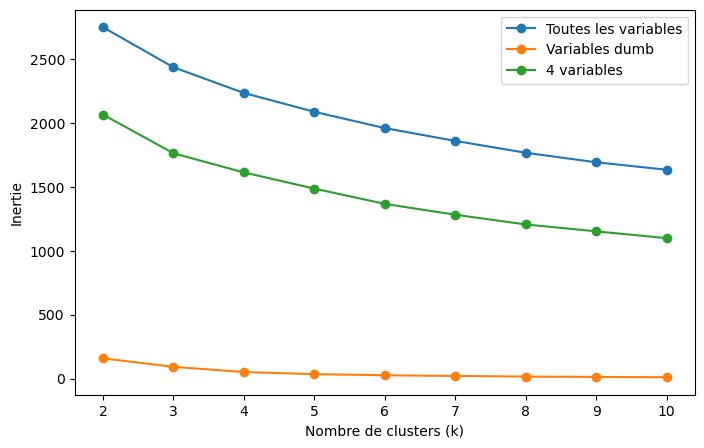

In [35]:
plt.figure(figsize=(8,5))
plt.plot(k_range, inerties, marker='o', label='Toutes les variables')
plt.plot(k_range, inerties_dumb, marker='o', label='Variables dumb')
plt.plot(k_range, inerties_four, marker='o', label='4 variables')
plt.xlabel("Nombre de clusters (k)")
plt.ylabel("Inertie")
plt.legend()
plt.show()

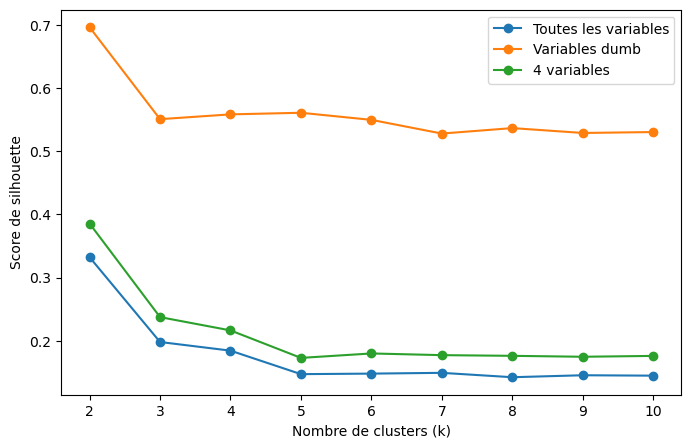

In [36]:
plt.figure(figsize=(8,5))
plt.plot(k_range, silhouettes, marker='o', label='Toutes les variables')
plt.plot(k_range, silhouettes_dumb, marker='o', label='Variables dumb')
plt.plot(k_range, silhouettes_four, marker='o', label='4 variables')
plt.xlabel("Nombre de clusters (k)")
plt.ylabel("Score de silhouette")
plt.legend()
plt.show()

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score


km_cv_configs = {
    "K-Means Dumb model": X_dumb,
    "K-Means 4 couples": X_four,
    "K-Means Toutes les variables": X_all,
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

km_cv_results = {}         # métriques par fold, pour la moyenne/std
km_y_pred_cv_store = {}    # prédictions concaténées sur tous les folds, pour la matrice de confusion

for name, X in km_cv_configs.items():
    y = y_all if "Toutes" in name else (y_dumb if "Dumb" in name else y_four)  
    
    fold_metrics = {"accuracy": [], "precision": [], "recall": [], "f1": []}
    y_true_all, y_pred_all = [], []

    for train_idx, test_idx in skf.split(X, y):
        X_train_fold, X_test_fold = X.iloc[train_idx], X.iloc[test_idx]
        y_train_fold, y_test_fold = y.iloc[train_idx], y.iloc[test_idx]

        km = KMeans(n_clusters=2, random_state=42, n_init=50)
        km.fit(X_train_fold)  
        y_pred_fold = km.predict(X_test_fold)

        
        if accuracy_score(y_test_fold, y_pred_fold) < 0.5:
            y_pred_fold = 1 - y_pred_fold

        fold_metrics["accuracy"].append(accuracy_score(y_test_fold, y_pred_fold))
        fold_metrics["precision"].append(precision_score(y_test_fold, y_pred_fold))
        fold_metrics["recall"].append(recall_score(y_test_fold, y_pred_fold))
        fold_metrics["f1"].append(f1_score(y_test_fold, y_pred_fold))

        y_true_all.extend(y_test_fold)
        y_pred_all.extend(y_pred_fold)

    km_cv_results[name] = {k: np.array(v) for k, v in fold_metrics.items()}
    km_y_pred_cv_store[name] = (np.array(y_true_all), np.array(y_pred_all))

    print(f"\n{'=' * 60}")
    print(f"  {name}")
    print(f"{'=' * 60}")
    for metric, vals in km_cv_results[name].items():
        print(f"  {metric:10s} : {vals.mean():.3f} (+/- {vals.std():.3f})  |  folds: {np.round(vals, 3)}")

K-Means est différent des modèles précédents car c'est un algorithme de clustering non supervisé. Il n'utilise pas les étiquettes des données d'entraînement (y_train) et cherche uniquement à regrouper les observations similaires. Les autres modèles sont des algorithmes de classification supervisée qui apprennent directement à distinguer les vrais des faux billets.

Dans cette étude, K-Means n'est pas l'algorithme le plus intuitivement pertinent puisque nous disposons déjà des étiquettes des billets. Les méthodes de classification supervisée sembleraient donc plus adaptées. Toutefois, les très bons résultats obtenus avec K-Means montrent que les vrais et les faux billets forment naturellement deux groupes bien distincts dans l'espace des variables et que l'idée qu'un modèle non supervisé performe sur ce jeu de données n'est pas à rejeter.

<div style="background-color:#A5D6A7; padding:20px; border-left:6px solid #2E7D32; border-radius:8px;">

### Modèle supplémentaire : tentative d'évaluation par paires de variables

Jusque là les modèles testés ont évaluer les variables de manière univariée. A la vue des conclusions tirées de l'exploration initiale et de l'OVL nous sommes curieux d'évaluer le comportement d'un modèle qui évalue les variables par paires.

Nous proposons d'utiliser le KDE pour représenter la densité de probabilité de chacune des classes dans un espace à deux dimensions. Le modèle effectuera ces prédictions subséquentes en projetant les nouveaux éléments à évaluer sur cet espace et en comparant les probabilités associées des deux classes. 

Nota Bene : Après plusieurs tests, nous nous sommes rendus que ce modèle obtenait les meilleures résultats avec seulement deux paires (trois variables distinctes) de variables (les paires les plus discriminantes selon l'OVL).

</div>

In [40]:
import numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from scipy.stats import gaussian_kde

pairs = [
    ("margin_low", "length"),
    ("margin_up", "length"),
]

X_kde = X_scaled[['length', 'margin_low', "margin_up"]]
y_kde = X_scaled['is_genuine']

GRID_SIZE = 200


def run_kde_fold(X_train_fold, y_train_fold, X_test_fold):
    """Reproduit exactement ton pipeline KDE (fit + grille + prédiction) sur un fold donné."""
    grid_store = {}
    for xi, xj in pairs:
        x0 = X_train_fold.loc[y_train_fold == False, [xi, xj]].values
        x1 = X_train_fold.loc[y_train_fold == True, [xi, xj]].values

        kde0 = gaussian_kde(x0.T)
        kde1 = gaussian_kde(x1.T)

        x_min, y_min = X_train_fold[[xi, xj]].min().values
        x_max, y_max = X_train_fold[[xi, xj]].max().values
        x_edges = np.linspace(x_min, x_max, GRID_SIZE)
        y_edges = np.linspace(y_min, y_max, GRID_SIZE)
        xx, yy = np.meshgrid(x_edges, y_edges)
        grid_pts = np.vstack([xx.ravel(), yy.ravel()])

        f0 = kde0(grid_pts).reshape(xx.shape)
        f1 = kde1(grid_pts).reshape(xx.shape)

        p1 = f1 / (f0 + f1 + 1e-300)
        p0 = 1 - p1

        grid_store[(xi, xj)] = {"x_edges": x_edges, "y_edges": y_edges, "p0": p0, "p1": p1}

    p0_sum = np.zeros(len(X_test_fold))
    p1_sum = np.zeros(len(X_test_fold))

    for xi, xj in pairs:
        store = grid_store[(xi, xj)]
        xvals = X_test_fold[xi].values
        yvals = X_test_fold[xj].values

        ix = np.clip(np.searchsorted(store["x_edges"], xvals) - 1, 0, GRID_SIZE - 1)
        iy = np.clip(np.searchsorted(store["y_edges"], yvals) - 1, 0, GRID_SIZE - 1)

        p0_sum += store["p0"][iy, ix]
        p1_sum += store["p1"][iy, ix]

    return p1_sum > p0_sum


# ============================================================
# Boucle sur les 5 folds — toutes les métriques stockées par fold
# ============================================================
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

fold_metrics = {"accuracy": [], "precision": [], "recall": [], "f1": []}
y_true_all, y_pred_all = [], []

for train_idx, test_idx in skf.split(X_kde, y_kde):
    X_train_fold = X_kde.iloc[train_idx]
    y_train_fold = y_kde.iloc[train_idx]
    X_test_fold = X_kde.iloc[test_idx]
    y_test_fold = y_kde.iloc[test_idx]

    y_pred_fold = run_kde_fold(X_train_fold, y_train_fold, X_test_fold)

    fold_metrics["accuracy"].append(accuracy_score(y_test_fold, y_pred_fold))
    fold_metrics["precision"].append(precision_score(y_test_fold, y_pred_fold))
    fold_metrics["recall"].append(recall_score(y_test_fold, y_pred_fold))
    fold_metrics["f1"].append(f1_score(y_test_fold, y_pred_fold))

    y_true_all.extend(y_test_fold)
    y_pred_all.extend(y_pred_fold)

fold_metrics = {k: np.array(v) for k, v in fold_metrics.items()}
y_test_kde_cv = np.array(y_true_all)
y_pred_kde_cv = np.array(y_pred_all)

for metric, vals in fold_metrics.items():
    print(f"{metric:10s} : {vals.mean():.3f} (+/- {vals.std():.3f})  |  folds: {np.round(vals, 3)}")

accuracy   : 0.990 (+/- 0.003)  |  folds: [0.986 0.993 0.99  0.99  0.993]
precision  : 0.994 (+/- 0.006)  |  folds: [0.985 1.    0.995 0.99  1.   ]
recall     : 0.992 (+/- 0.003)  |  folds: [0.995 0.99  0.99  0.995 0.99 ]
f1         : 0.993 (+/- 0.002)  |  folds: [0.99  0.995 0.992 0.992 0.995]


# Sélection du meilleur modèle

In [42]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, classification_report



<div style="background-color:#4A90E2; padding:18px 22px; border-left:6px solid #357ABD; border-radius:8px;">

# **LOGISTIC REGRESSION**

</div>

In [44]:
results = []
for name, scores in cv_results.items():
    results.append({
        "Modèle": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Accuracy (std)": scores["test_accuracy"].std(),
        "Precision": scores["test_precision"].mean(),
        "Precision (std)": scores["test_precision"].std(),
        "Recall": scores["test_recall"].mean(),
        "Recall (std)": scores["test_recall"].std(),
        "F1-score": scores["test_f1"].mean(),
        "F1-score (std)": scores["test_f1"].std(),
    })

results_df = pd.DataFrame(results)

display(
    results_df.style
    .format({col: "{:.3f}" for col in results_df.columns if col != "Modèle"})
    .background_gradient(
        subset=["Accuracy", "Precision", "Recall", "F1-score"],
        cmap="Blues"
    )
    .set_caption("Comparaison des performances des modèles (moyenne 5 folds)")
)

,Modèle,Accuracy,Accuracy (std),Precision,Precision (std),Recall,Recall (std),F1-score,F1-score (std)
0,Dumb model,0.956,0.003,0.957,0.008,0.978,0.007,0.967,0.002
1,4 couples,0.992,0.003,0.991,0.007,0.997,0.003,0.994,0.003
2,Toutes les variables,0.991,0.005,0.991,0.007,0.996,0.002,0.993,0.003


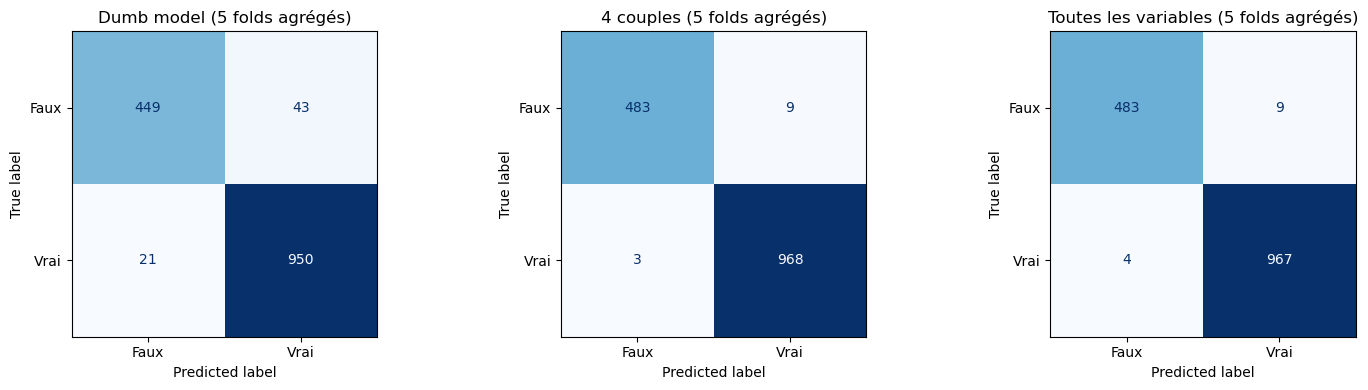


  Dumb model
              precision    recall  f1-score   support

        Faux      0.955     0.913     0.933       492
        Vrai      0.957     0.978     0.967       971

    accuracy                          0.956      1463
   macro avg      0.956     0.945     0.950      1463
weighted avg      0.956     0.956     0.956      1463


  4 couples
              precision    recall  f1-score   support

        Faux      0.994     0.982     0.988       492
        Vrai      0.991     0.997     0.994       971

    accuracy                          0.992      1463
   macro avg      0.992     0.989     0.991      1463
weighted avg      0.992     0.992     0.992      1463


  Toutes les variables
              precision    recall  f1-score   support

        Faux      0.992     0.982     0.987       492
        Vrai      0.991     0.996     0.993       971

    accuracy                          0.991      1463
   macro avg      0.991     0.989     0.990      1463
weighted avg      0.991

In [45]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

y_pred_cv_store = {}

for ax, (name, (model, X, y)) in zip(axes, cv_configs.items()):
    y_pred_cv = cross_val_predict(model, X, y, cv=skf)
    y_pred_cv_store[name] = (y, y_pred_cv)

    cm = confusion_matrix(y, y_pred_cv)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Faux", "Vrai"])
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{name} (5 folds agrégés)")

plt.tight_layout()
plt.show()

# ============================================================
# Rapports de classification (sur les prédictions agrégées des 5 folds)
# ============================================================
for name, (y_true, y_pred) in y_pred_cv_store.items():
    print(f"\n{'=' * 60}")
    print(f"  {name}")
    print(f"{'=' * 60}")
    print(classification_report(y_true, y_pred, target_names=["Faux", "Vrai"], digits=3))

<div style="background-color:#F4A261; padding:18px 22px; border-left:6px solid #E76F51; border-radius:8px;">

# **K-NEAREST NEIGHBORS**

</div>

In [47]:
knn_results = []
for name, scores in knn_cv_results.items():
    knn_results.append({
        "Modèle": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Accuracy (std)": scores["test_accuracy"].std(),
        "Precision": scores["test_precision"].mean(),
        "Precision (std)": scores["test_precision"].std(),
        "Recall": scores["test_recall"].mean(),
        "Recall (std)": scores["test_recall"].std(),
        "F1-score": scores["test_f1"].mean(),
        "F1-score (std)": scores["test_f1"].std(),
    })

knn_results_df = pd.DataFrame(knn_results)

display(
    knn_results_df.style
    .format({col: "{:.3f}" for col in knn_results_df.columns if col != "Modèle"})
    .background_gradient(
        subset=["Accuracy", "Precision", "Recall", "F1-score"],
        cmap="Oranges"
    )
    .set_caption("Comparaison des performances — KNN (moyenne 5 folds)")
)

,Modèle,Accuracy,Accuracy (std),Precision,Precision (std),Recall,Recall (std),F1-score,F1-score (std)
0,KNN Dumb model,0.955,0.007,0.952,0.012,0.981,0.007,0.967,0.005
1,KNN 4 couples,0.990,0.004,0.988,0.005,0.997,0.004,0.992,0.003
2,KNN Toutes les variables,0.988,0.006,0.986,0.007,0.997,0.003,0.991,0.004


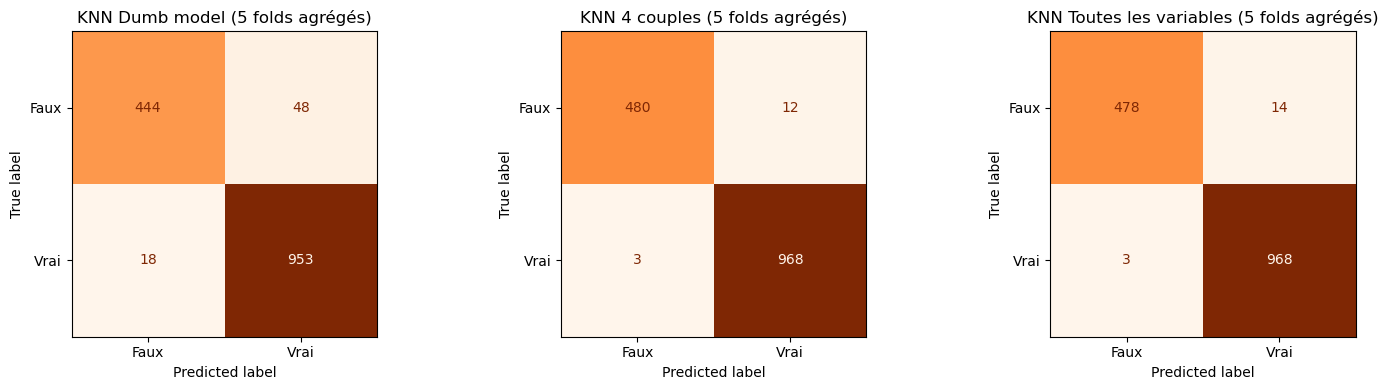


  KNN Dumb model
              precision    recall  f1-score   support

        Faux      0.961     0.902     0.931       492
        Vrai      0.952     0.981     0.967       971

    accuracy                          0.955      1463
   macro avg      0.957     0.942     0.949      1463
weighted avg      0.955     0.955     0.955      1463


  KNN 4 couples
              precision    recall  f1-score   support

        Faux      0.994     0.976     0.985       492
        Vrai      0.988     0.997     0.992       971

    accuracy                          0.990      1463
   macro avg      0.991     0.986     0.988      1463
weighted avg      0.990     0.990     0.990      1463


  KNN Toutes les variables
              precision    recall  f1-score   support

        Faux      0.994     0.972     0.983       492
        Vrai      0.986     0.997     0.991       971

    accuracy                          0.988      1463
   macro avg      0.990     0.984     0.987      1463
weighted av

In [48]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

knn_y_pred_cv_store = {}

for ax, (name, (model, X, y)) in zip(axes, knn_cv_configs.items()):
    y_pred_cv = cross_val_predict(model, X, y, cv=skf)
    knn_y_pred_cv_store[name] = (y, y_pred_cv)

    cm = confusion_matrix(y, y_pred_cv)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Faux", "Vrai"])
    disp.plot(ax=ax, cmap="Oranges", colorbar=False)
    ax.set_title(f"{name} (5 folds agrégés)")

plt.tight_layout()
plt.show()

# ============================================================
# Rapports de classification (sur les prédictions agrégées des 5 folds)
# ============================================================
for name, (y_true, y_pred) in knn_y_pred_cv_store.items():
    print(f"\n{'=' * 60}")
    print(f"  {name}")
    print(f"{'=' * 60}")
    print(classification_report(y_true, y_pred, target_names=["Faux", "Vrai"], digits=3))

<div style="background-color:#A5D6A7; padding:18px 22px; border-left:6px solid #2E7D32; border-radius:8px;">

# **RANDOM FOREST**

</div>

In [50]:
rf_results = []
for name, scores in rf_cv_results.items():
    rf_results.append({
        "Modèle": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Accuracy (std)": scores["test_accuracy"].std(),
        "Precision": scores["test_precision"].mean(),
        "Precision (std)": scores["test_precision"].std(),
        "Recall": scores["test_recall"].mean(),
        "Recall (std)": scores["test_recall"].std(),
        "F1-score": scores["test_f1"].mean(),
        "F1-score (std)": scores["test_f1"].std(),
    })

rf_results_df = pd.DataFrame(rf_results)

display(
    rf_results_df.style
    .format({col: "{:.3f}" for col in rf_results_df.columns if col != "Modèle"})
    .background_gradient(
        subset=["Accuracy", "Precision", "Recall", "F1-score"],
        cmap="Greens"
    )
    .set_caption("Comparaison des performances — Random Forest (moyenne 5 folds)")
)

,Modèle,Accuracy,Accuracy (std),Precision,Precision (std),Recall,Recall (std),F1-score,F1-score (std)
0,RF Dumb model,0.952,0.007,0.952,0.012,0.977,0.012,0.964,0.006
1,RF 4 couples,0.988,0.003,0.988,0.007,0.995,0.005,0.991,0.002
2,RF Toutes les variables,0.990,0.004,0.989,0.007,0.997,0.003,0.993,0.003


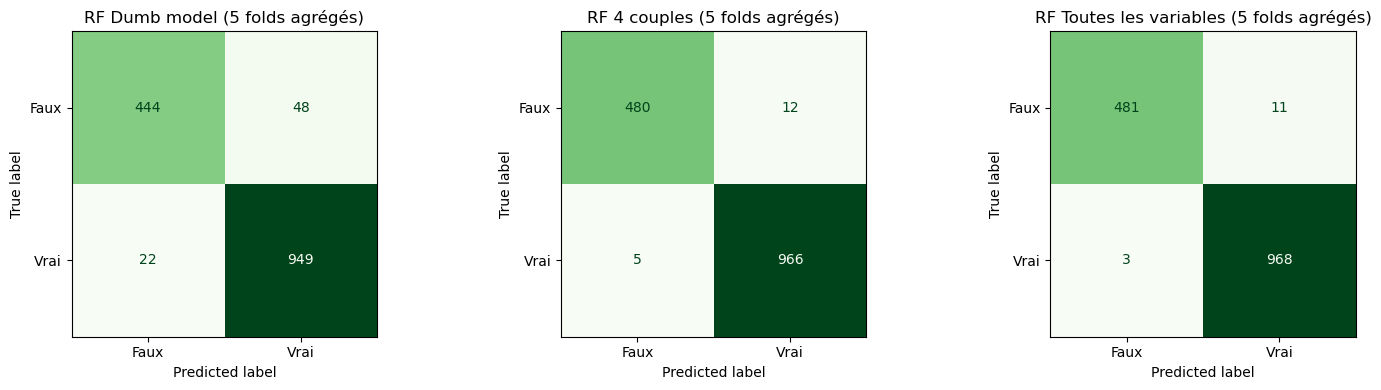


  RF Dumb model
              precision    recall  f1-score   support

        Faux      0.953     0.902     0.927       492
        Vrai      0.952     0.977     0.964       971

    accuracy                          0.952      1463
   macro avg      0.952     0.940     0.946      1463
weighted avg      0.952     0.952     0.952      1463


  RF 4 couples
              precision    recall  f1-score   support

        Faux      0.990     0.976     0.983       492
        Vrai      0.988     0.995     0.991       971

    accuracy                          0.988      1463
   macro avg      0.989     0.985     0.987      1463
weighted avg      0.988     0.988     0.988      1463


  RF Toutes les variables
              precision    recall  f1-score   support

        Faux      0.994     0.978     0.986       492
        Vrai      0.989     0.997     0.993       971

    accuracy                          0.990      1463
   macro avg      0.991     0.987     0.989      1463
weighted avg  

In [51]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

rf_y_pred_cv_store = {}

for ax, (name, (model, X, y)) in zip(axes, rf_cv_configs.items()):
    y_pred_cv = cross_val_predict(model, X, y, cv=skf)
    rf_y_pred_cv_store[name] = (y, y_pred_cv)

    cm = confusion_matrix(y, y_pred_cv)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Faux", "Vrai"])
    disp.plot(ax=ax, cmap="Greens", colorbar=False)
    ax.set_title(f"{name} (5 folds agrégés)")

plt.tight_layout()
plt.show()

# ============================================================
# Rapports de classification (sur les prédictions agrégées des 5 folds)
# ============================================================
for name, (y_true, y_pred) in rf_y_pred_cv_store.items():
    print(f"\n{'=' * 60}")
    print(f"  {name}")
    print(f"{'=' * 60}")
    print(classification_report(y_true, y_pred, target_names=["Faux", "Vrai"], digits=3))

<div style="background-color:#A855F7; padding:18px 22px; border-left:6px solid #7E22CE; border-radius:8px;">

# **K MEAN**

</div>

In [53]:
km_results = []
for name, scores in km_cv_results.items():
    km_results.append({
        "Modèle": name,
        "Accuracy": scores["accuracy"].mean(),
        "Accuracy (std)": scores["accuracy"].std(),
        "Precision": scores["precision"].mean(),
        "Precision (std)": scores["precision"].std(),
        "Recall": scores["recall"].mean(),
        "Recall (std)": scores["recall"].std(),
        "F1-score": scores["f1"].mean(),
        "F1-score (std)": scores["f1"].std(),
    })

km_results_df = pd.DataFrame(km_results)

display(
    km_results_df.style
    .format({col: "{:.3f}" for col in km_results_df.columns if col != "Modèle"})
    .background_gradient(
        subset=["Accuracy", "Precision", "Recall", "F1-score"],
        cmap="Purples"
    )
    .set_caption("Comparaison des performances — K-Means (moyenne 5 folds)")
)

,Modèle,Accuracy,Accuracy (std),Precision,Precision (std),Recall,Recall (std),F1-score,F1-score (std)
0,K-Means Dumb model,0.955,0.007,0.940,0.010,0.996,0.004,0.967,0.005
1,K-Means 4 couples,0.984,0.009,0.986,0.011,0.990,0.003,0.988,0.007
2,K-Means Toutes les variables,0.986,0.007,0.987,0.009,0.993,0.003,0.990,0.005


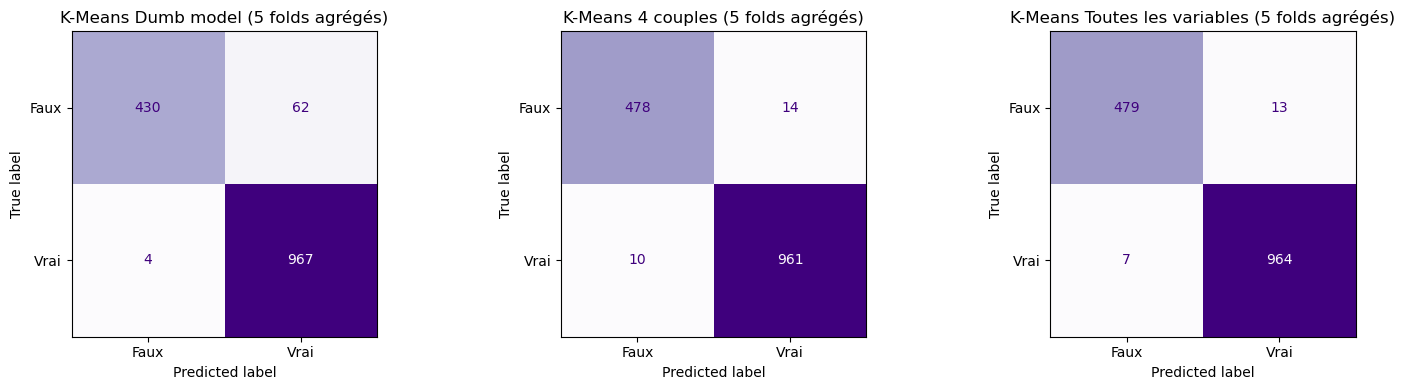


  K-Means Dumb model
              precision    recall  f1-score   support

        Faux      0.991     0.874     0.929       492
        Vrai      0.940     0.996     0.967       971

    accuracy                          0.955      1463
   macro avg      0.965     0.935     0.948      1463
weighted avg      0.957     0.955     0.954      1463


  K-Means 4 couples
              precision    recall  f1-score   support

        Faux      0.980     0.972     0.976       492
        Vrai      0.986     0.990     0.988       971

    accuracy                          0.984      1463
   macro avg      0.983     0.981     0.982      1463
weighted avg      0.984     0.984     0.984      1463


  K-Means Toutes les variables
              precision    recall  f1-score   support

        Faux      0.986     0.974     0.980       492
        Vrai      0.987     0.993     0.990       971

    accuracy                          0.986      1463
   macro avg      0.986     0.983     0.985      1463

In [54]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, (y_true, y_pred)) in zip(axes, km_y_pred_cv_store.items()):
    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Faux", "Vrai"])
    disp.plot(ax=ax, cmap="Purples", colorbar=False)
    ax.set_title(f"{name} (5 folds agrégés)")

plt.tight_layout()
plt.show()

# ============================================================
# Rapports de classification (sur les prédictions agrégées des 5 folds)
# ============================================================
for name, (y_true, y_pred) in km_y_pred_cv_store.items():
    print(f"\n{'=' * 60}")
    print(f"  {name}")
    print(f"{'=' * 60}")
    print(classification_report(y_true, y_pred, target_names=["Faux", "Vrai"], digits=3))

<div style="background-color:#EF4444; padding:18px 22px; border-left:6px solid #B91C1C; border-radius:8px;">

# **KDE**

</div>

,Modèle,Accuracy,Accuracy (std),Precision,Precision (std),Recall,Recall (std),F1-score,F1-score (std)
0,Ensemble KDE,0.990,0.003,0.994,0.006,0.992,0.003,0.993,0.002


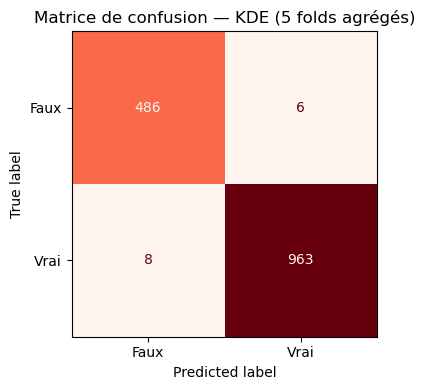


RAPPORT DE CLASSIFICATION — ENSEMBLE KDE (5 folds)
              precision    recall  f1-score   support

        Faux      0.984     0.988     0.986       492
        Vrai      0.994     0.992     0.993       971

    accuracy                          0.990      1463
   macro avg      0.989     0.990     0.989      1463
weighted avg      0.990     0.990     0.990      1463



In [56]:

# ============================================================
# 1. Tableau des performances (moyenne + std par métrique)
# ============================================================
results_kde = pd.DataFrame({
    "Modèle": ["Ensemble KDE"],
    "Accuracy": [fold_metrics["accuracy"].mean()],
    "Accuracy (std)": [fold_metrics["accuracy"].std()],
    "Precision": [fold_metrics["precision"].mean()],
    "Precision (std)": [fold_metrics["precision"].std()],
    "Recall": [fold_metrics["recall"].mean()],
    "Recall (std)": [fold_metrics["recall"].std()],
    "F1-score": [fold_metrics["f1"].mean()],
    "F1-score (std)": [fold_metrics["f1"].std()],
})

display(
    results_kde.style
    .format({col: "{:.3f}" for col in results_kde.columns if col != "Modèle"})
    .background_gradient(
        subset=["Accuracy", "Precision", "Recall", "F1-score"],
        cmap="Blues"
    )
    .set_caption("Performances — Ensemble KDE (moyenne 5 folds)")
)

# ============================================================
# 2. Matrice de confusion (5 folds agrégés)
# ============================================================
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(
    confusion_matrix(y_test_kde_cv, y_pred_kde_cv),
    display_labels=["Faux", "Vrai"]
).plot(
    ax=ax,
    cmap="Reds",
    colorbar=False
)
ax.set_title("Matrice de confusion — KDE (5 folds agrégés)")
plt.tight_layout()
plt.show()

# ============================================================
# 3. Rapport de classification
# ============================================================
print("\n" + "=" * 55)
print("RAPPORT DE CLASSIFICATION — ENSEMBLE KDE (5 folds)")
print("=" * 55)
print(
    classification_report(
        y_test_kde_cv,
        y_pred_kde_cv,
        target_names=["Faux", "Vrai"],
        digits=3
    )
)

<div style="background-color:#4A4A4A; padding:20px; border-left:6px solid #212121; border-radius:8px; color:white;">

### Sélection du modèle final

La comparaison des modèles ne peut se limiter à la seule accuracy : elle doit également intégrer le contexte métier. Dans notre cas, l'erreur la plus pénalisante consiste à prédire un billet comme vrai alors qu'il est en réalité faux — un faux billet qui passerait le contrôle. À l'inverse, un billet vrai prédit comme faux reste une erreur mineure : elle peut être rattrapée par un contrôle complémentaire.

**Étape 1 — Comparaison de l'accuracy**

| Modèle | Accuracy | Écart-type |
|---|---|---|
| Régression logistique (4 couples) | 0.992 | 0.003 |
| Régression logistique (5 variables) | 0.991 | 0.005 |
| KNN (4 couples) | 0.990 | 0.004 |
| Random Forest (5 variables) | 0.990 | 0.004 |
| Ensemble KDE (2 pairs) | 0.990 | 0.003 |
| K-Means (5 variables) | 0.986 | 0.007 |

Le K-Means affiche la performance la plus faible des six modèles : il est écarté à ce stade.

**Étape 2 — Stabilité (écart-type)**

Le KNN et le Random Forest présentent un écart-type plus élevé (0.004) que la régression logistique et l'ensemble KDE (0.003), pour une accuracy équivalente ou inférieure. Ils sont donc écartés à leur tour, au profit des deux modèles les plus stables sur l'ensemble des folds.

**Étape 3 — Arbitrage final sur le recall**

Entre la régression logistique (4 couples) et l'ensemble KDE, l'accuracy et la stabilité sont proches. La décision se fait donc sur le critère métier prioritaire : le recall de la classe "Faux", c'est-à-dire la capacité du modèle à détecter effectivement les faux billets.

- Ensemble KDE : recall = 0.990
- Régression logistique (4 couples) : recall = 0.989

**Conclusion : l'ensemble KDE est retenu comme modèle final**, en raison de sa meilleure détection des faux billets — le critère le plus déterminant au regard du risque métier.

</div>

# Sauvegarde du meilleur modèle

In [59]:
from sklearn.pipeline import make_pipeline
import joblib

<div style="background-color:#A5D6A7; padding:20px; border-left:6px solid #2E7D32; border-radius:8px;">
    
Mise en œuvre du modèle KDE par paires

Nous mettons ici en œuvre le modèle KDE présenté précédemment. Nous retenons les trois variables correspondant aux deux paires les plus discriminantes identifiées lors de l'analyse par OVL : length avec margin_low, puis length avec margin_up.

Avant l'entraînement, les observations présentant des valeurs manquantes dans les variables utilisées ou dans la variable cible sont retirées. Les variables sont ensuite standardisées afin de placer les différentes mesures sur une échelle comparable.

Le modèle est alors entraîné sur l'ensemble des données disponibles. Pour chacune des deux paires, il estime séparément la densité des billets authentiques et contrefaits dans un espace à deux dimensions, puis construit une grille de probabilités permettant d'associer rapidement une nouvelle observation à l'une des deux classes.

Enfin, l'ensemble du pipeline — comprenant la standardisation et le modèle KDE — est sauvegardé au format .joblib. Cela permet de réutiliser directement le modèle lors de la phase de déploiement, sans avoir à reproduire manuellement les étapes de préparation des données.

</div>

In [61]:
from sklearn.base import BaseEstimator, ClassifierMixin

class KDEPairEnsembleClassifier(BaseEstimator, ClassifierMixin):
    def __init__(self, feature_cols, pairs, grid_size=200):
        self.feature_cols = feature_cols
        self.pairs = pairs
        self.grid_size = grid_size

    def fit(self, X, y):
        X = np.asarray(X)
        y = np.asarray(y)
        self.classes_ = np.unique(y)
        c0, c1 = self.classes_

        self.grid_store_ = {}
        for xi, xj in self.pairs:
            ix = self.feature_cols.index(xi)
            jx = self.feature_cols.index(xj)

            x0 = X[y == c0][:, [ix, jx]]
            x1 = X[y == c1][:, [ix, jx]]

            kde0 = gaussian_kde(x0.T)
            kde1 = gaussian_kde(x1.T)

            x_min, y_min = X[:, [ix, jx]].min(axis=0)
            x_max, y_max = X[:, [ix, jx]].max(axis=0)
            x_edges = np.linspace(x_min, x_max, self.grid_size)
            y_edges = np.linspace(y_min, y_max, self.grid_size)
            xx, yy = np.meshgrid(x_edges, y_edges)
            grid_pts = np.vstack([xx.ravel(), yy.ravel()])

            f0 = kde0(grid_pts).reshape(xx.shape)
            f1 = kde1(grid_pts).reshape(xx.shape)

            p1 = f1 / (f0 + f1 + 1e-300)
            p0 = 1 - p1

            self.grid_store_[(xi, xj)] = {
                "x_edges": x_edges, "y_edges": y_edges, "p0": p0, "p1": p1
            }

        return self

    def predict(self, X):
        X = np.asarray(X)
        p0_sum = np.zeros(len(X))
        p1_sum = np.zeros(len(X))

        for (xi, xj), store in self.grid_store_.items():
            ix = self.feature_cols.index(xi)
            jx = self.feature_cols.index(xj)

            xvals = X[:, ix]
            yvals = X[:, jx]

            ixg = np.clip(np.searchsorted(store["x_edges"], xvals) - 1, 0, self.grid_size - 1)
            iyg = np.clip(np.searchsorted(store["y_edges"], yvals) - 1, 0, self.grid_size - 1)

            p0_sum += store["p0"][iyg, ixg]
            p1_sum += store["p1"][iyg, ixg]

        return np.where(p1_sum > p0_sum, self.classes_[1], self.classes_[0])

In [62]:

feature_cols = ["length", "margin_low", "margin_up"]
pairs = [("margin_low", "length"), ("margin_up", "length")]

# X et y
X_raw = df[feature_cols].copy()
y_raw = df["is_genuine"].copy()

# ============================================================
# Suppression des lignes contenant au moins un NA dans X ou y
# ============================================================

mask = X_raw.notna().all(axis=1) & y_raw.notna()

X_raw = X_raw.loc[mask]
y_raw = y_raw.loc[mask]

print(f"Nombre de lignes conservées : {len(X_raw)}")
print(f"Nombre de lignes supprimées : {len(df) - len(X_raw)}")

# ============================================================
# Pipeline
# ============================================================

pipeline = make_pipeline(
    StandardScaler(),
    KDEPairEnsembleClassifier(
        feature_cols=feature_cols,
        pairs=pairs,
        grid_size=200
    )
)

pipeline.fit(X_raw, y_raw)

# Sauvegarde
joblib.dump(pipeline, "kde_ensemble_model.joblib")

print("✅ Modèle sauvegardé : kde_ensemble_model.joblib")


Nombre de lignes conservées : 1463
Nombre de lignes supprimées : 37
✅ Modèle sauvegardé : kde_ensemble_model.joblib


<div style="background-color:#A5D6A7; padding:20px; border-left:6px solid #2E7D32; border-radius:8px;">
    
Mise en œuvre du modèle de régression logistique

Nous mettons ici en œuvre le modèle de régression logistique retenu à partir de la sélection des variables. Celui-ci utilise cinq caractéristiques : length, margin_low, margin_up, height_right et height_left, avec is_genuine comme variable cible.

Comme précédemment, les observations comportant des valeurs manquantes dans les variables explicatives ou dans la variable cible sont écartées avant l'entraînement. Cette étape permet notamment de garantir que le modèle puisse être entraîné sans erreur liée aux données manquantes.

Les variables sont ensuite standardisées afin de rendre leurs échelles comparables, puis transmises à une régression logistique. Ces deux étapes sont regroupées au sein d'un même pipeline, ce qui permet de conserver exactement le même traitement des données lors de la phase de déploiement.

Le modèle est finalement entraîné sur l'ensemble des observations propres disponibles, puis sauvegardé au format .joblib. Le pipeline ainsi enregistré pourra être directement réutilisé pour effectuer des prédictions sur de nouveaux billets, sans avoir à appliquer manuellement la standardisation.

</div>

In [64]:

import numpy as np
import pandas as pd
import joblib

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression


# ============================================================
# 1. Charger les données
# ============================================================

df = pd.read_csv(DATA_PATH, sep=";")


# ============================================================
# 2. Variables utilisées par le modèle
# ============================================================

feature_cols = [
    "length",
    "margin_low",
    "margin_up",
    "height_right",
    "height_left"
]

target_col = "is_genuine"


# ============================================================
# 3. Construire X et y
# ============================================================

X = df[feature_cols].copy()
y = df[target_col].copy()


# ============================================================
# 4. Supprimer les lignes contenant des NA
# ============================================================

mask = X.notna().all(axis=1) & y.notna()

X_clean = X.loc[mask].copy()
y_clean = y.loc[mask].copy()

print(f"Nombre de lignes originales : {len(df)}")
print(f"Nombre de lignes conservées : {len(X_clean)}")
print(f"Nombre de lignes supprimées : {len(df) - len(X_clean)}")


# Vérification des NA
print("\nNA restants dans X :")
print(X_clean.isna().sum())

print("\nNA restants dans y :")
print(y_clean.isna().sum())


# ============================================================
# 5. Pipeline : StandardScaler + Logistic Regression
# ============================================================

lr_four_pipeline = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)


# ============================================================
# 6. Entraîner le modèle sur toutes les données propres
# ============================================================

lr_four_pipeline.fit(X_clean, y_clean)

print("\n✅ Modèle entraîné")


# ============================================================
# 7. Sauvegarder le pipeline complet
# ============================================================

MODEL_PATH = "logistic_regression_4_couples.joblib"

joblib.dump(
    lr_four_pipeline,
    MODEL_PATH
)

print(f"✅ Modèle sauvegardé : {MODEL_PATH}")


Nombre de lignes originales : 1500
Nombre de lignes conservées : 1463
Nombre de lignes supprimées : 37

NA restants dans X :
length          0
margin_low      0
margin_up       0
height_right    0
height_left     0
dtype: int64

NA restants dans y :
0

✅ Modèle entraîné
✅ Modèle sauvegardé : logistic_regression_4_couples.joblib
